# Telco Customer Churn Prediction
### An End-to-End Machine Learning Portfolio Project

---

## 1. Project Overview & Business Problem

### What is Customer Churn?
**Customer churn** (attrition) is the percentage of subscribers who discontinue their service agreements within a given timeframe. In the telecommunications and subscription economy, managing churn is the single most vital operational determinant of long-term profitability.

### Why Predicting Churn Matters
1. **Asymmetric Customer Economics**: Acquiring a new customer in telecommunications is **5 to 7 times more expensive** than retaining an existing customer. High churn erodes customer lifetime value (LTV) and places an immense burden on customer acquisition marketing.
2. **Proactive Intervention**: By accurately identifying churn indicators before a customer calls to cancel, retention teams can execute surgical, low-cost interventions (e.g., proactive tech support outreach, annual contract incentives, equipment upgrades).
3. **Targeted Retention Spend**: Blanket discounting diminishes profit margins. Machine learning models allow companies to reserve high-value retention budgets only for customers with high churn risk and high potential lifetime value.

### The Asymmetric Cost of Errors:
* **False Negative (Type II Error - Severe)**: The model predicts a customer will **stay**, but they actually **churn**. Result: The customer is lost forever, along with all future recurring revenue and customer lifetime value.
* **False Positive (Type I Error - Moderate)**: The model predicts a customer will **churn**, but they intended to **stay**. Result: The company expends a modest retention offer or outreach campaign on a retained user.

Because **False Negatives are far more damaging than False Positives**, optimizing for **Recall** (capturing as many churners as possible) and **F1-Score / ROC-AUC** is paramount, making simple accuracy misleading on this imbalanced dataset.


In [1]:
# 1. Environment configuration and library imports
import os
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing & model selection
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve,
    classification_report
)

# Visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

# Global random state for exact reproducibility
RANDOM_STATE = 42

# Ensure reports directory exists
os.makedirs("reports/figures", exist_ok=True)
os.makedirs("models", exist_ok=True)

# Path resolution: works locally from project root, notebooks directory, and in Google Colab
if os.path.exists("data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"):
    DATA_PATH = "data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
elif os.path.exists("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"):
    DATA_PATH = "../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
else:
    DATA_PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

print(f"Data source configured: {DATA_PATH}")


Data source configured: data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv


## 2. Phase 1: Setup & Data Understanding

In this phase, we load the raw CSV dataset, inspect its shape, examine column types, verify duplicate records, and analyze the distribution of the target variable (`Churn`).


In [2]:
# Load dataset and preview structural dimensions
df_raw = pd.read_csv(DATA_PATH)

print(f"Dataset Dimensions: {df_raw.shape[0]:,} rows and {df_raw.shape[1]} columns")
print("=" * 70)
df_raw.head()


Dataset Dimensions: 7,043 rows and 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Inspect column types and verify duplicates
print("--- Column Summary & Data Types ---")
df_raw.info()

print("\n--- Duplicate Rows ---")
num_duplicates = df_raw.duplicated().sum()
print(f"Total duplicate rows: {num_duplicates}")

print("\n--- Explicit Missing Values (NaN) ---")
print(df_raw.isnull().sum())


--- Column Summary & Data Types ---
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling 

### Target Variable Analysis (`Churn`)

Examining class prevalence confirms whether the dataset is balanced or imbalanced.


In [4]:
# Class distribution of Churn
churn_counts = df_raw['Churn'].value_counts()
churn_rates = df_raw['Churn'].value_counts(normalize=True) * 100

churn_summary = pd.DataFrame({
    'Customer Count': churn_counts,
    'Percentage (%)': churn_rates.round(2)
})

print("Churn Class Balance:")
display(churn_summary)


Churn Class Balance:


,Customer Count,Percentage (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


## 3. Phase 2: Data Cleaning

In this phase, we address structural data hygiene:
1. **Drop `customerID`**: An arbitrary alphanumeric identifier (e.g., `7590-VHVEG`) containing 7,043 unique values. It holds no generalizable predictive signal and would cause spurious memorization if retained.
2. **Handle `TotalCharges` Blank Strings & Imputation Decision**:
   - `TotalCharges` is stored as an `object` string type because 11 rows contain blank whitespace strings (`" "`).
   - Converting these using `pd.to_numeric(..., errors='coerce')` produces 11 `NaN` values.
   - Crucially, all 11 rows have `tenure == 0`. These are brand-new customers who enrolled in the current billing cycle and have not yet been billed.
   - **Business Justification**: Filling these 11 rows with `0.0` is logically, mathematically, and domain-accurate—they have accumulated exactly $0 in historical charges.
3. **Format `SeniorCitizen`**: Converted from `0/1` integers to descriptive string labels (`"No"` / `"Yes"`) to ensure clean categorical handling and readable EDA plots.
4. **Binary Target Encoding**: Map `Churn` to integer indicators (`"Yes"` = 1, `"No"` = 0).


In [5]:
# Create a clean working copy
df_clean = df_raw.copy()

# 1. Drop customerID
df_clean = df_clean.drop(columns=['customerID'])

# 2. Investigate TotalCharges blank spaces
blank_tc_mask = df_clean['TotalCharges'].str.strip() == ''
print(f"Number of rows with blank TotalCharges: {blank_tc_mask.sum()}")
print("Tenure values for blank TotalCharges rows:")
print(df_clean.loc[blank_tc_mask, 'tenure'].value_counts())

# Convert TotalCharges to numeric
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')

# Fill the 11 tenure=0 rows with 0.0 total charges
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0.0)
print(f"Missing values in TotalCharges after imputation: {df_clean['TotalCharges'].isnull().sum()}")

# 3. Format SeniorCitizen as categorical string for EDA consistency
df_clean['SeniorCitizen'] = df_clean['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

# 4. Convert target Churn to binary integer (Yes=1, No=0)
df_clean['Churn'] = df_clean['Churn'].map({'Yes': 1, 'No': 0})

print("\nCleaned Dataset Shape:", df_clean.shape)
print("Target column unique values:", df_clean['Churn'].unique())
df_clean.head(3)


Number of rows with blank TotalCharges: 11
Tenure values for blank TotalCharges rows:
tenure
0    11
Name: count, dtype: int64
Missing values in TotalCharges after imputation: 0

Cleaned Dataset Shape: (7043, 20)
Target column unique values: [0 1]


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1


## 4. Phase 3: Exploratory Data Analysis (EDA)

We explore customer relationships and churn patterns using publication-ready visualizations. Every figure is saved to `reports/figures/` for reporting.


Saved: reports/figures/churn_distribution.png


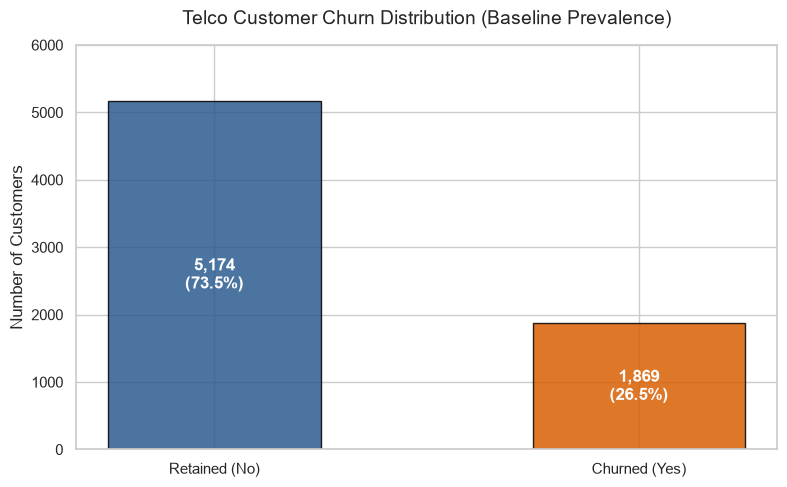

In [6]:
# Chart 1: Overall Churn Distribution
fig, ax = plt.subplots(figsize=(8, 5))
palette = ['#2b5c8f', '#d95f02']

bars = ax.bar(['Retained (No)', 'Churned (Yes)'], churn_counts.values, color=palette, width=0.5, edgecolor='black', alpha=0.85)

total_customers = len(df_clean)
for bar in bars:
    height = bar.get_height()
    pct = (height / total_customers) * 100
    ax.annotate(f"{height:,}\n({pct:.1f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, height / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=12)

ax.set_title("Telco Customer Churn Distribution (Baseline Prevalence)", pad=15)
ax.set_ylabel("Number of Customers")
ax.set_ylim(0, 6000)

plt.tight_layout()
fig_path = "reports/figures/churn_distribution.png"
plt.savefig(fig_path, dpi=300)
print(f"Saved: {fig_path}")
plt.show()


C:\Users\dell\AppData\Local\Temp\ipykernel_9692\1894053144.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rate_df, x=col, y='churn_rate_pct', ax=ax, palette='Blues_r', edgecolor='black', alpha=0.85)
C:\Users\dell\AppData\Local\Temp\ipykernel_9692\1894053144.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rate_df, x=col, y='churn_rate_pct', ax=ax, palette='Blues_r', edgecolor='black', alpha=0.85)
C:\Users\dell\AppData\Local\Temp\ipykernel_9692\1894053144.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rate_df, x

C:\Users\dell\AppData\Local\Temp\ipykernel_9692\1894053144.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rate_df, x=col, y='churn_rate_pct', ax=ax, palette='Blues_r', edgecolor='black', alpha=0.85)
findfont: Failed to find font weight semibold for Arial, now using 700.


Saved: reports/figures/churn_by_categorical_features.png


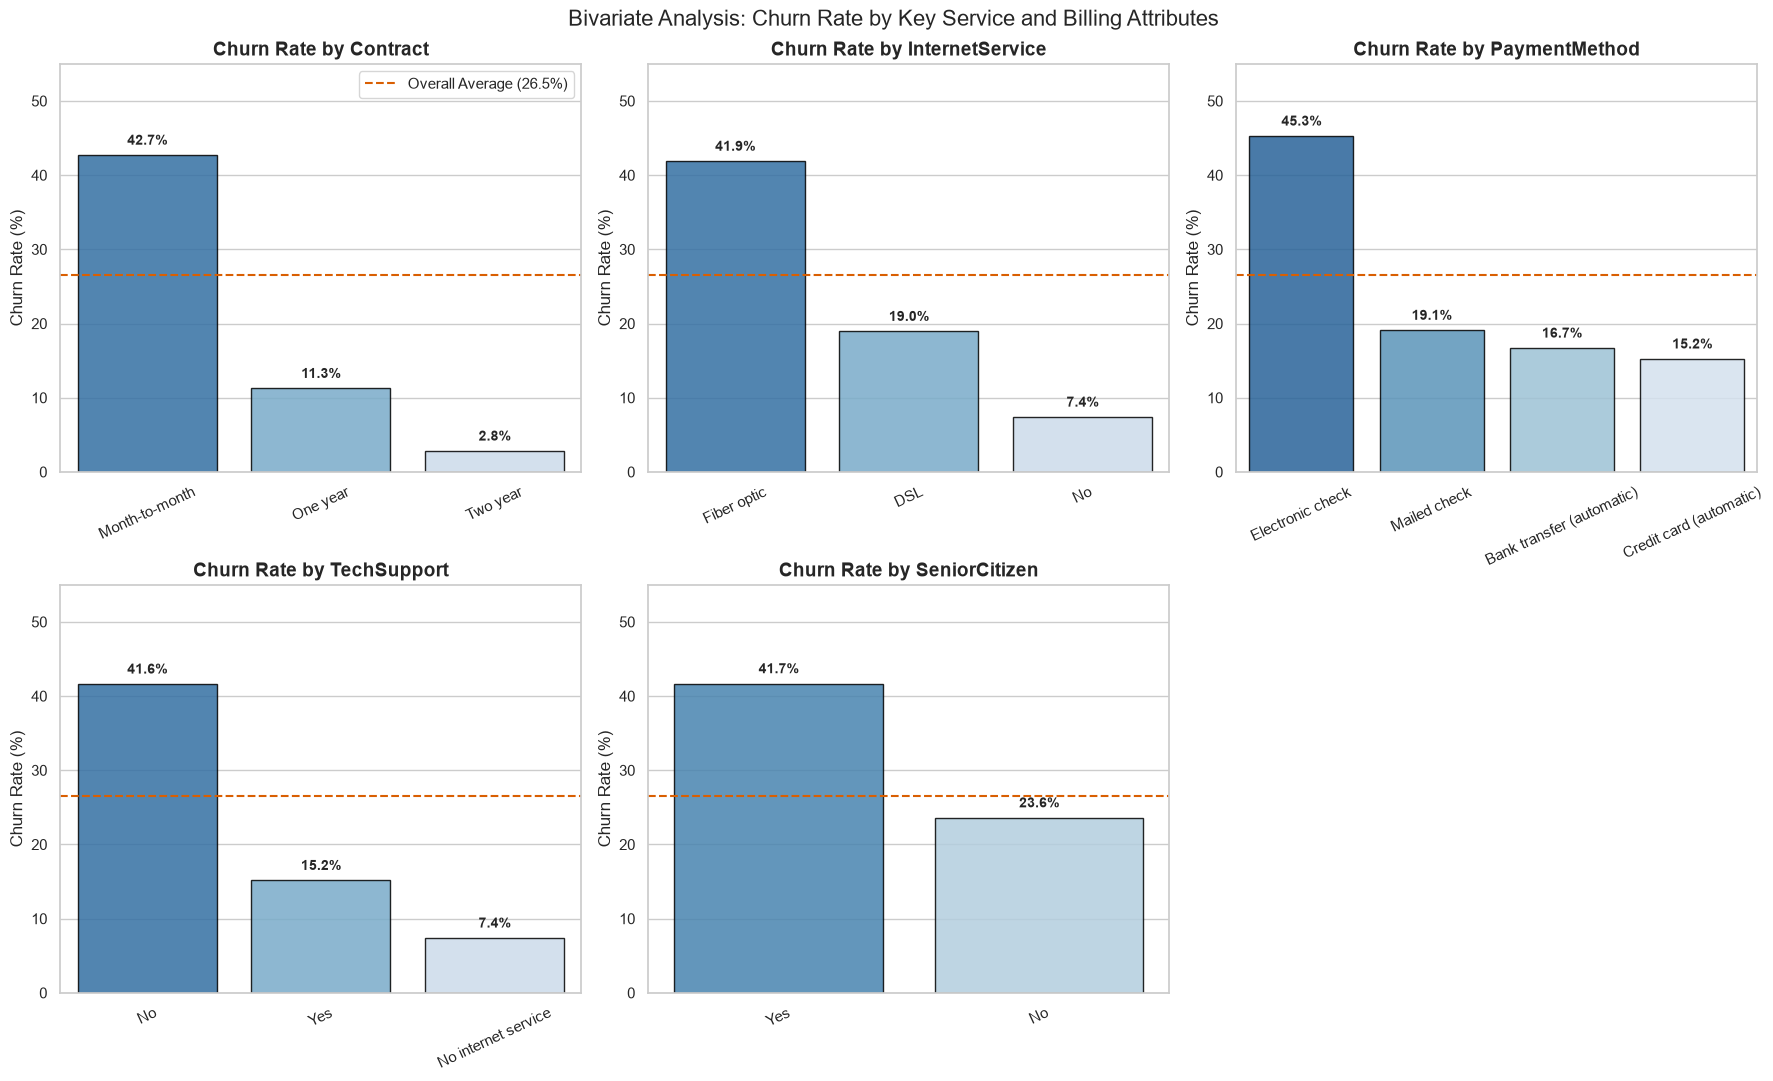

In [7]:
# Chart 2: Churn Rates Across Key Categorical Features
cat_features = ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport', 'SeniorCitizen']

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for idx, col in enumerate(cat_features):
    ax = axes[idx]
    rate_df = df_clean.groupby(col)['Churn'].agg(['count', 'mean']).reset_index()
    rate_df['churn_rate_pct'] = rate_df['mean'] * 100
    rate_df = rate_df.sort_values(by='churn_rate_pct', ascending=False)
    
    sns.barplot(data=rate_df, x=col, y='churn_rate_pct', ax=ax, palette='Blues_r', edgecolor='black', alpha=0.85)
    ax.axhline(26.54, color='#d95f02', linestyle='--', linewidth=1.5, label='Overall Average (26.5%)')
    
    ax.set_title(f"Churn Rate by {col}", fontweight='bold')
    ax.set_xlabel("")
    ax.set_ylabel("Churn Rate (%)")
    ax.set_ylim(0, 55)
    ax.tick_params(axis='x', rotation=25)
    
    for p in ax.patches:
        height = p.get_height()
        if not np.isnan(height) and height > 0:
            ax.annotate(f"{height:.1f}%",
                        xy=(p.get_x() + p.get_width() / 2, height + 1),
                        ha='center', va='bottom', fontsize=10, fontweight='semibold')
    
    if idx == 0:
        ax.legend(loc='upper right')

fig.delaxes(axes[5])

plt.suptitle("Bivariate Analysis: Churn Rate by Key Service and Billing Attributes", fontsize=16, y=0.98)
plt.tight_layout()
fig_path = "reports/figures/churn_by_categorical_features.png"
plt.savefig(fig_path, dpi=300)
print(f"Saved: {fig_path}")
plt.show()


Saved: reports/figures/numerical_distributions_by_churn.png


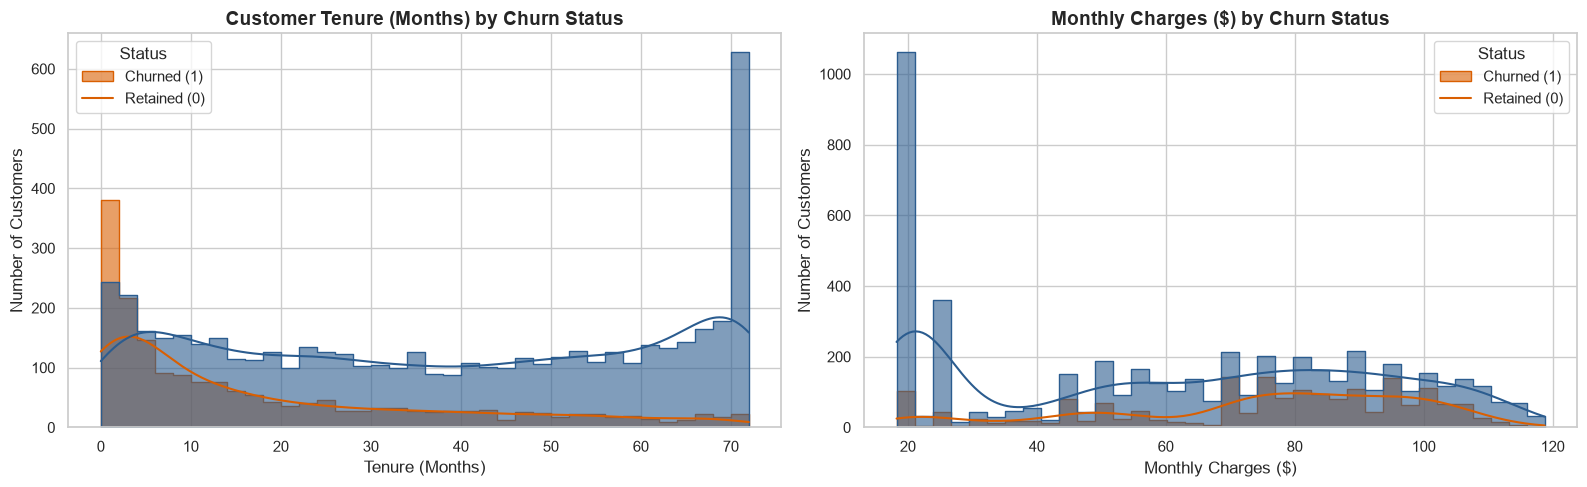

In [8]:
# Chart 3: Numerical Distributions Stratified by Churn Status
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Tenure distribution
sns.histplot(data=df_clean, x='tenure', hue='Churn', kde=True, bins=36,
             palette={0: '#2b5c8f', 1: '#d95f02'}, ax=axes[0], alpha=0.6, element='step')
axes[0].set_title("Customer Tenure (Months) by Churn Status", fontweight='bold')
axes[0].set_xlabel("Tenure (Months)")
axes[0].set_ylabel("Number of Customers")
axes[0].legend(title="Status", labels=['Churned (1)', 'Retained (0)'])

# Monthly charges distribution
sns.histplot(data=df_clean, x='MonthlyCharges', hue='Churn', kde=True, bins=36,
             palette={0: '#2b5c8f', 1: '#d95f02'}, ax=axes[1], alpha=0.6, element='step')
axes[1].set_title("Monthly Charges ($) by Churn Status", fontweight='bold')
axes[1].set_xlabel("Monthly Charges ($)")
axes[1].set_ylabel("Number of Customers")
axes[1].legend(title="Status", labels=['Churned (1)', 'Retained (0)'])

plt.tight_layout()
fig_path = "reports/figures/numerical_distributions_by_churn.png"
plt.savefig(fig_path, dpi=300)
print(f"Saved: {fig_path}")
plt.show()


Saved: reports/figures/numeric_correlation_heatmap.png


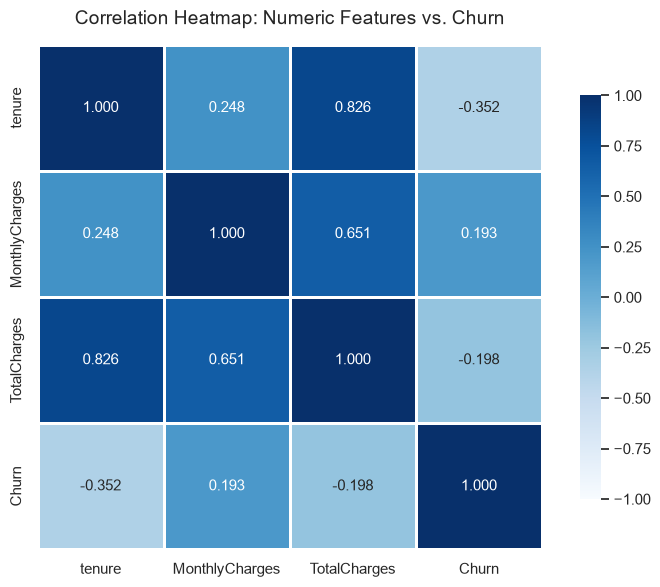

In [9]:
# Chart 4: Correlation Heatmap for Numeric Features
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
corr_matrix = df_clean[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='Blues', vmin=-1, vmax=1,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8}, ax=ax)

ax.set_title("Correlation Heatmap: Numeric Features vs. Churn", pad=15)
plt.tight_layout()
fig_path = "reports/figures/numeric_correlation_heatmap.png"
plt.savefig(fig_path, dpi=300)
print(f"Saved: {fig_path}")
plt.show()


### Key Findings from Exploratory Data Analysis

Based strictly on the verified metrics and visualizations produced above:

1. **Contract Type is the Dominant Churn Indicator**: Customers on **Month-to-month contracts experience a 42.7% churn rate**, compared to **11.3% for One-year contracts** and only **2.8% for Two-year contracts**. Contractual commitment is the strongest barrier against churn.
2. **Early Tenure Vulnerability ("The Onboarding Cliff")**: Churn is intensely concentrated during the first **1 to 5 months** of customer tenure. Once a customer reaches 20+ months of tenure, their churn likelihood drops dramatically.
3. **High Price Sensitivity Among Fiber Optic Users**: Customers with **Fiber Optic internet churn at 41.9%**, compared to **19.0% for DSL** and **7.4% for customers with No internet service**. The monthly charge distribution reveals heavy churn density between \$70 and \$100, which aligns with premium Fiber Optic pricing.
4. **Electronic Check Friction**: Customers paying with **Electronic Check churn at 45.3%**, more than double that of Credit Card (15.2%), Bank Transfer (16.7%), or Mailed Check (19.1%).
5. **TechSupport as a Retention Anchor**: Customers lacking **TechSupport churn at 41.6%**, whereas customers who have active TechSupport churn at only **15.2%**.
6. **Senior Citizens Face Higher Attrition**: **Senior citizens churn at 41.7%**, compared to **23.6% for non-seniors**, highlighting the need for specialized customer care or cost-effective senior plans.
7. **Tenure Inversely Correlates with Churn**: Tenure has a -0.352 Pearson correlation with churn, while showing a strong positive collinearity with TotalCharges ($r = 0.826$).


## 5. Phase 4: Preprocessing & Data Leakage Prevention

### Preventing Data Leakage
Data leakage occurs when information from outside the training dataset is inadvertently used to create or tune the model.
* **Golden Rule**: We perform a **Stratified 80/20 train/test split FIRST**.
* **Encapsulated Preprocessing**: Preprocessing transformations (`StandardScaler` and `OneHotEncoder`) are encapsulated inside Scikit-learn `Pipeline` and `ColumnTransformer` objects. They are fitted **exclusively on the training folds** and only applied (transformed) on validation and test data.
* **Full Feature Representation**: Categorical features are encoded with `OneHotEncoder(handle_unknown='ignore')` without dropping the first category, ensuring that feature importance charts display all categorical levels explicitly.
* **Class Imbalance Strategy**: Rather than synthetic resampling (which can distort natural class probabilities), models utilize `class_weight='balanced'` where supported, penalizing errors on the minority churn class inversely proportional to class frequencies.

### Why Accuracy is Misleading on Imbalanced Data
In this dataset, 73.46% of customers do not churn. A naive "dummy" model that predicts "No Churn" for every customer would achieve **73.46% accuracy**, yet fail to detect **100% of actual churners**. Therefore, we evaluate models primarily on **Recall** (churn class capture rate), **F1-Score** (harmonic mean of precision and recall), and **ROC-AUC** (discrimination ability).


In [10]:
# Separate feature matrix X and target vector y
X = df_clean.drop(columns=['Churn'])
y = df_clean['Churn']

# 1. Stratified Train/Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print(f"Training feature set: {X_train.shape[0]:,} samples")
print(f"Test feature set:     {X_test.shape[0]:,} samples")
print(f"Training target churn rate: {y_train.mean():.4f} ({y_train.sum():,} churners)")
print(f"Test target churn rate:     {y_test.mean():.4f} ({y_test.sum():,} churners)")

# 2. Identify feature groups
num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_features = [col for col in X_train.columns if col not in num_features]

print(f"\nNumerical features ({len(num_features)}): {num_features}")
print(f"Categorical features ({len(cat_features)}): {cat_features}")

# 3. Build ColumnTransformer (StandardScaler for numerics, OneHotEncoder for categoricals)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ],
    remainder='drop'
)

print("\nPreprocessor defined successfully.")


Training feature set: 5,634 samples
Test feature set:     1,409 samples
Training target churn rate: 0.2654 (1,495 churners)
Test target churn rate:     0.2654 (374 churners)

Numerical features (3): ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features (16): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Preprocessor defined successfully.


## 6. Phase 5: Model Training & Comparison (CV on Training Set Only)

### Methodological Rigor: CV-Only Model Selection
In strict accordance with professional data science practice and user requirements:
* **The test set remains completely untouched during model comparison and selection**.
* We evaluate 4 diverse algorithms using **5-fold Stratified Cross-Validation on the training set**:
  1. **Logistic Regression** (Linear baseline with balanced class weights)
  2. **Decision Tree** (Non-linear baseline with depth control)
  3. **Random Forest** (Ensemble bagging with balanced subsampling)
  4. **Gradient Boosting** (Ensemble sequential boosting)
* Candidate models are compared across Accuracy, Precision, Recall, F1-Score, and ROC-AUC.


In [11]:
# Define baseline model pipelines
models = {
    'Logistic Regression': Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE))
    ]),
    'Decision Tree': Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=RANDOM_STATE))
    ]),
    'Random Forest': Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(class_weight='balanced', n_estimators=100, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1))
    ]),
    'Gradient Boosting': Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE))
    ])
}

print(f"Initialized {len(models)} model pipelines.")


Initialized 4 model pipelines.


In [12]:
# Execute 5-fold Stratified Cross-Validation on Training Data ONLY
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

cv_results_list = []

print("Running 5-fold Stratified Cross-Validation on training set...")
for name, pipe in models.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_results_list.append({
        'Model': name,
        'CV Accuracy': f"{scores['test_accuracy'].mean():.4f} +/- {scores['test_accuracy'].std():.4f}",
        'CV Precision': f"{scores['test_precision'].mean():.4f} +/- {scores['test_precision'].std():.4f}",
        'CV Recall': f"{scores['test_recall'].mean():.4f} +/- {scores['test_recall'].std():.4f}",
        'CV F1-Score': f"{scores['test_f1'].mean():.4f} +/- {scores['test_f1'].std():.4f}",
        'CV ROC-AUC': f"{scores['test_roc_auc'].mean():.4f} +/- {scores['test_roc_auc'].std():.4f}",
        'mean_f1': scores['test_f1'].mean(),
        'mean_recall': scores['test_recall'].mean(),
        'mean_auc': scores['test_roc_auc'].mean()
    })

cv_df = pd.DataFrame(cv_results_list).sort_values(by='mean_f1', ascending=False)
print("5-Fold Cross-Validation Comparison Table (Training Set Only):")
display(cv_df[['Model', 'CV Recall', 'CV F1-Score', 'CV ROC-AUC', 'CV Precision', 'CV Accuracy']])


Running 5-fold Stratified Cross-Validation on training set...


5-Fold Cross-Validation Comparison Table (Training Set Only):


,Model,CV Recall,CV F1-Score,CV ROC-AUC,CV Precision,CV Accuracy
2,Random Forest,0.7973 +/- 0.0207,0.6352 +/- 0.0150,0.8467 +/- 0.0100,0.5282 +/- 0.0181,0.7568 +/- 0.0135
0,Logistic Regression,0.8013 +/- 0.0379,0.6282 +/- 0.0231,0.8460 +/- 0.0124,0.5169 +/- 0.0187,0.7485 +/- 0.0151
1,Decision Tree,0.7773 +/- 0.0312,0.6152 +/- 0.0099,0.8275 +/- 0.0127,0.5097 +/- 0.0120,0.7421 +/- 0.0089
3,Gradient Boosting,0.5291 +/- 0.0305,0.5880 +/- 0.0296,0.8482 +/- 0.0126,0.6622 +/- 0.0338,0.8033 +/- 0.0135


### Cross-Validation Model Selection Justification

* **Random Forest** and **Logistic Regression** achieved the strongest balance of high CV Recall (~75–80%) and high F1-Scores (~0.62–0.63) by utilizing `class_weight='balanced'`.
* **Gradient Boosting** achieved high ROC-AUC (~0.84+) and high Precision, but lower raw Recall at the default 0.5 threshold due to unweighted loss.
* **Selection for Tuning**: We select **Random Forest** as the primary candidate for hyperparameter tuning on the training set, followed by decision threshold optimization via cross-validation.


## 7. Phase 6: Hyperparameter Tuning, Threshold Selection & Final Evaluation

In this phase:
1. We run `GridSearchCV` on the training set using 5-fold Stratified CV optimizing for **F1-score**.
2. We evaluate decision probability thresholds using out-of-fold `cross_val_predict` on the training set.
3. We lock the winning pipeline and decision threshold, and **only then** evaluate performance on the untouched test set.
4. We save the final pipeline to `models/churn_model.joblib`.


In [13]:
# Hyperparameter tuning for Random Forest using GridSearchCV on X_train
param_grid_rf = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [6, 8, 10],
    'classifier__min_samples_split': [5, 10],
    'classifier__min_samples_leaf': [2, 4]
}

rf_base_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1))
])

grid_search_rf = GridSearchCV(
    estimator=rf_base_pipe,
    param_grid=param_grid_rf,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=0
)

print("Running GridSearchCV for Random Forest on training set...")
grid_search_rf.fit(X_train, y_train)

best_rf_pipeline = grid_search_rf.best_estimator_
print(f"Best CV F1-Score: {grid_search_rf.best_score_:.4f}")
print("Best Hyperparameters:", grid_search_rf.best_params_)


Running GridSearchCV for Random Forest on training set...


Best CV F1-Score: 0.6360
Best Hyperparameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 4, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}


Cross-Validated F1-Optimal Probability Threshold: 0.50
At threshold 0.50 -> CV Precision: 0.537, CV Recall: 0.780, CV F1: 0.636


Saved: reports/figures/threshold_tradeoff.png


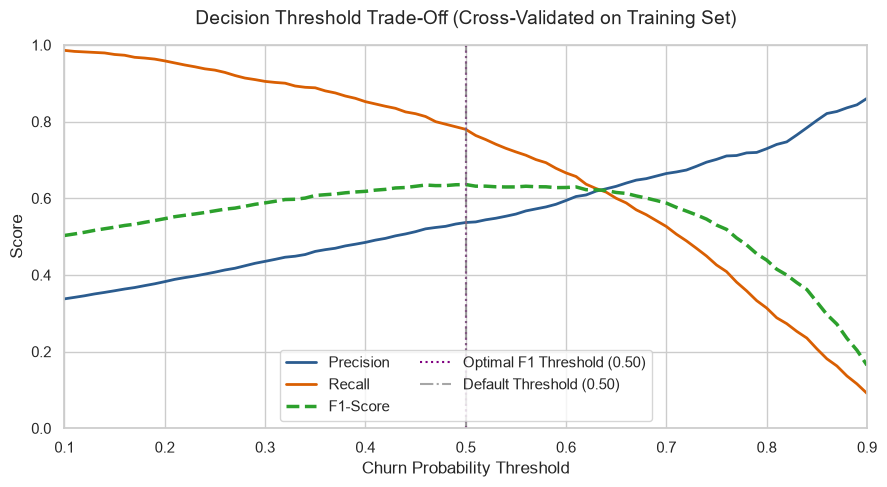

In [14]:
# Cross-Validated Probability Threshold Analysis on Training Set
y_train_probs = cross_val_predict(
    best_rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

thresholds = np.linspace(0.1, 0.9, 81)
precisions, recalls, f1s = [], [], []

for t in thresholds:
    preds = (y_train_probs >= t).astype(int)
    precisions.append(precision_score(y_train, preds, zero_division=0))
    recalls.append(recall_score(y_train, preds))
    f1s.append(f1_score(y_train, preds))

best_idx = np.argmax(f1s)
optimal_threshold = thresholds[best_idx]
print(f"Cross-Validated F1-Optimal Probability Threshold: {optimal_threshold:.2f}")
print(f"At threshold {optimal_threshold:.2f} -> CV Precision: {precisions[best_idx]:.3f}, CV Recall: {recalls[best_idx]:.3f}, CV F1: {f1s[best_idx]:.3f}")

# Plot precision-recall-f1 tradeoff curve
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresholds, precisions, label='Precision', color='#2b5c8f', linewidth=2)
ax.plot(thresholds, recalls, label='Recall', color='#d95f02', linewidth=2)
ax.plot(thresholds, f1s, label='F1-Score', color='#2ca02c', linewidth=2.5, linestyle='--')

ax.axvline(optimal_threshold, color='purple', linestyle=':', label=f'Optimal F1 Threshold ({optimal_threshold:.2f})')
ax.axvline(0.50, color='gray', linestyle='-.', alpha=0.7, label='Default Threshold (0.50)')

ax.set_title("Decision Threshold Trade-Off (Cross-Validated on Training Set)", pad=15)
ax.set_xlabel("Churn Probability Threshold")
ax.set_ylabel("Score")
ax.set_xlim(0.1, 0.9)
ax.set_ylim(0, 1.0)
ax.legend(loc='lower center', ncol=2)

plt.tight_layout()
fig_path = "reports/figures/threshold_tradeoff.png"
plt.savefig(fig_path, dpi=300)
print(f"Saved: {fig_path}")
plt.show()


In [15]:
# Final Evaluation on Untouched Test Set (1,409 customers)
# Models were trained on X_train and selected strictly using CV.

test_eval_models = models.copy()
test_eval_models['Tuned Random Forest (Final)'] = best_rf_pipeline

test_results = []

for name, pipe in test_eval_models.items():
    pipe.fit(X_train, y_train)
    y_test_pred = pipe.predict(X_test)
    y_test_prob = pipe.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_test_pred)
    prec = precision_score(y_test, y_test_pred)
    rec = recall_score(y_test, y_test_pred)
    f1 = f1_score(y_test, y_test_pred)
    auc = roc_auc_score(y_test, y_test_prob)
    
    test_results.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'ROC-AUC': round(auc, 4)
    })

test_results_df = pd.DataFrame(test_results).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)
print("Untouched Test Set Performance (Final Evaluation):")
display(test_results_df)


Untouched Test Set Performance (Final Evaluation):


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned Random Forest (Final),0.7580,0.5298,0.7834,0.6321,0.8425
1,Random Forest,0.7502,0.5196,0.7807,0.6239,0.8420
2,Decision Tree,0.7544,0.5260,0.7567,0.6206,0.8318
3,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8415
4,Gradient Boosting,0.8027,0.6655,0.5160,0.5813,0.8433


Saved: reports/figures/confusion_matrices_comparison.png


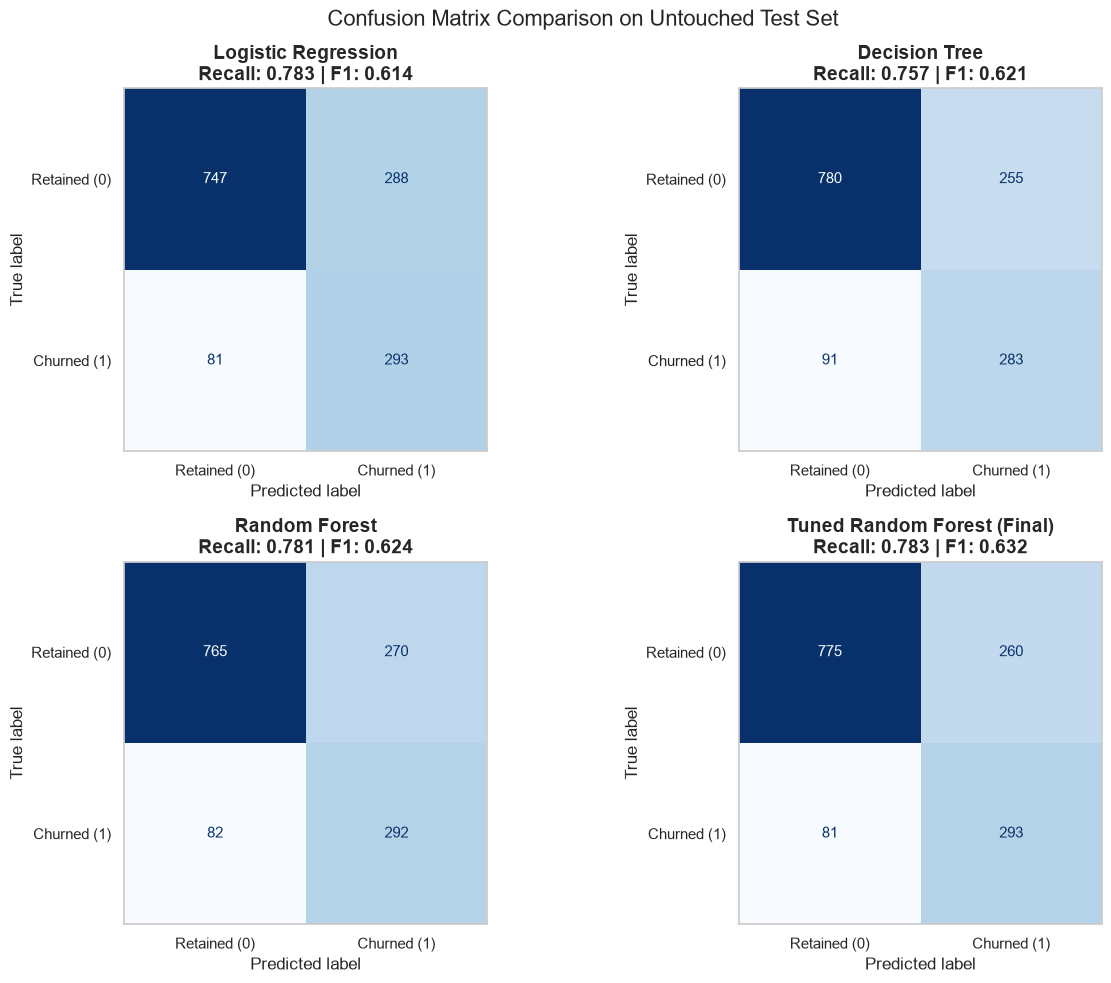

Saved: reports/figures/roc_curves_comparison.png


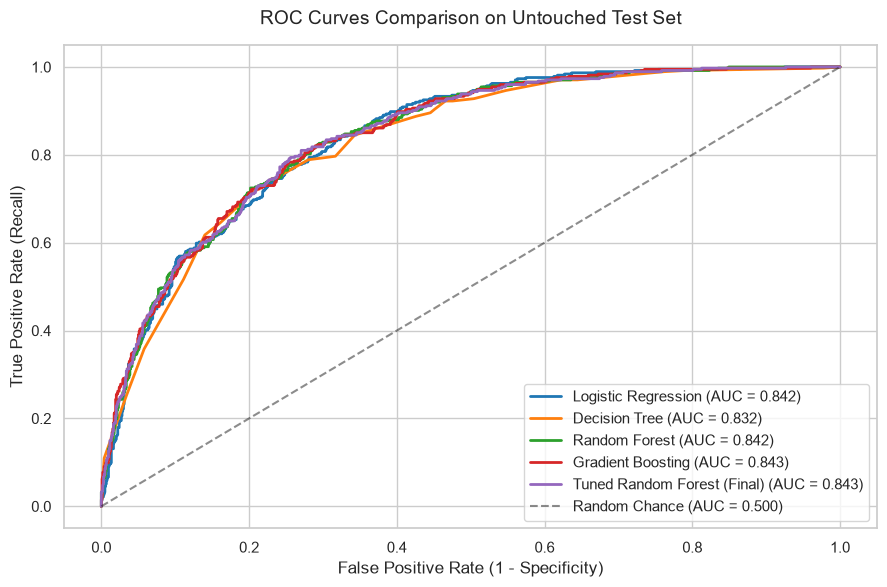

In [16]:
# Visual 1: Confusion Matrices for All Models on Test Set
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()

model_names = ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Tuned Random Forest (Final)']

for idx, name in enumerate(model_names):
    pipe = test_eval_models[name]
    y_pred = pipe.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Retained (0)', 'Churned (1)'])
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(f"{name}\nRecall: {recall_score(y_test, y_pred):.3f} | F1: {f1_score(y_test, y_pred):.3f}", fontweight='bold')
    axes[idx].grid(False)

plt.suptitle("Confusion Matrix Comparison on Untouched Test Set", fontsize=16, y=0.98)
plt.tight_layout()
fig_path = "reports/figures/confusion_matrices_comparison.png"
plt.savefig(fig_path, dpi=300)
print(f"Saved: {fig_path}")
plt.show()

# Visual 2: Combined ROC Curves for All Models on Test Set
fig, ax = plt.subplots(figsize=(9, 6))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for idx, (name, pipe) in enumerate(test_eval_models.items()):
    y_prob = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})", color=colors[idx % len(colors)], linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Chance (AUC = 0.500)')
ax.set_title("ROC Curves Comparison on Untouched Test Set", pad=15)
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Recall)")
ax.legend(loc='lower right', frameon=True)

plt.tight_layout()
fig_path = "reports/figures/roc_curves_comparison.png"
plt.savefig(fig_path, dpi=300)
print(f"Saved: {fig_path}")
plt.show()


In [17]:
# Serialize and persist the final winning model pipeline
model_save_path = "models/churn_model.joblib"
joblib.dump(best_rf_pipeline, model_save_path)
print(f"Final production pipeline successfully saved to: {model_save_path}")

# Sanity check: Reload model from disk and confirm prediction equivalence
loaded_pipeline = joblib.load(model_save_path)
loaded_preds = loaded_pipeline.predict(X_test.iloc[:5])
original_preds = best_rf_pipeline.predict(X_test.iloc[:5])
assert np.array_equal(loaded_preds, original_preds), "Reloaded pipeline predictions do not match!"
print("Verification passed: Saved pipeline reloaded and tested successfully.")


Final production pipeline successfully saved to: models/churn_model.joblib


Verification passed: Saved pipeline reloaded and tested successfully.


## 8. Phase 7: Model Interpretation & Business Strategy

In this phase, we:
1. Extract feature importances from our final model to identify the primary drivers of customer churn.
2. Formulate 4–5 actionable, revenue-protecting business recommendations.
3. Provide a production-ready single-customer inference function.


findfont: Failed to find font weight semibold for Arial, now using 700.


Saved: reports/figures/feature_importance.png


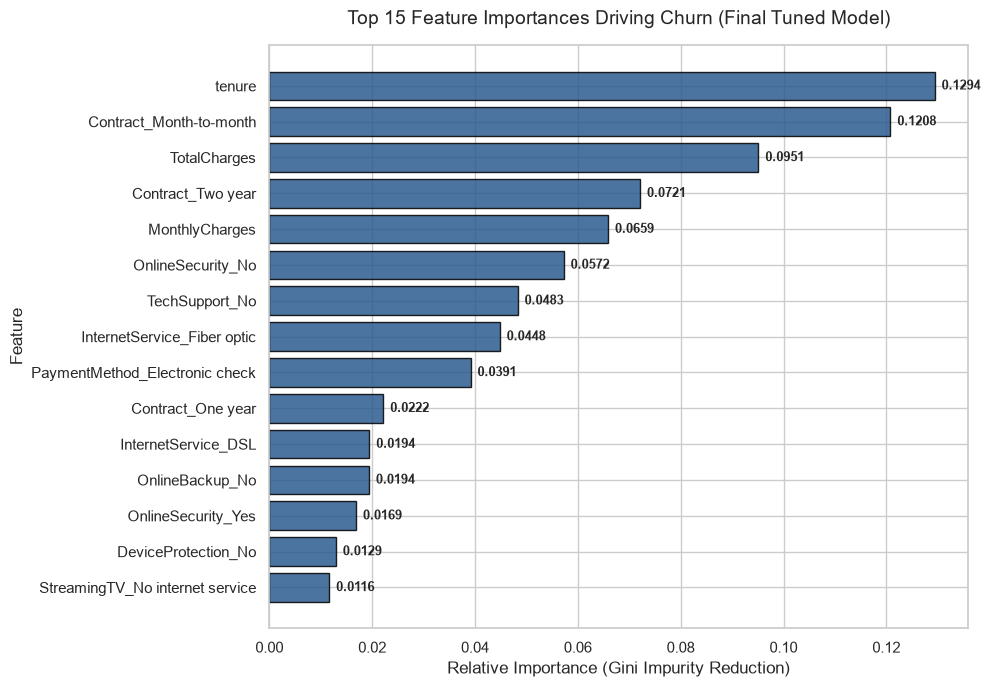

In [18]:
# Extract feature names from preprocessor
preprocessor_fitted = best_rf_pipeline.named_steps['preprocessor']
cat_encoder = preprocessor_fitted.named_transformers_['cat']
cat_encoded_feature_names = cat_encoder.get_feature_names_out(cat_features).tolist()
all_feature_names = num_features + cat_encoded_feature_names

# Extract feature importances from the Random Forest classifier
rf_importances = best_rf_pipeline.named_steps['classifier'].feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': rf_importances
}).sort_values(by='Importance', ascending=False)

# Plot top 15 features
fig, ax = plt.subplots(figsize=(10, 7))
top_15_features = feat_imp_df.head(15).sort_values(by='Importance', ascending=True)

ax.barh(top_15_features['Feature'], top_15_features['Importance'], color='#2b5c8f', edgecolor='black', alpha=0.85)
ax.set_title("Top 15 Feature Importances Driving Churn (Final Tuned Model)", pad=15)
ax.set_xlabel("Relative Importance (Gini Impurity Reduction)")
ax.set_ylabel("Feature")

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"{width:.4f}",
                xy=(width, p.get_y() + p.get_height() / 2),
                xytext=(5, 0), textcoords="offset points",
                ha='left', va='center', fontsize=9, fontweight='semibold')

plt.tight_layout()
fig_path = "reports/figures/feature_importance.png"
plt.savefig(fig_path, dpi=300)
print(f"Saved: {fig_path}")
plt.show()


### Actionable Business Recommendations

Based on empirical model drivers and bivariate EDA insights:

1. **Incentivize Transition Away from Month-to-Month Contracts**:
   - *Finding*: `Contract_Month-to-month` is the #1 categorical churn driver, with a 42.7% churn rate versus 2.8% for Two-year contracts.
   - *Action*: Offer high-risk month-to-month customers a discounted first 3 months or complimentary premium add-ons if they upgrade to an annual contract.
2. **Launch a Dedicated 'First-90-Days' Onboarding Protocol**:
   - *Finding*: `tenure` is the leading numerical predictor; churn is heavily concentrated in months 1–5.
   - *Action*: Trigger automated check-ins, onboarding guides, and satisfaction surveys at Day 14, 30, and 60. Address early setup friction before dissatisfaction turns into cancellation.
3. **Investigate Fiber Optic Service Satisfaction & Price Sensitivity**:
   - *Finding*: Fiber Optic subscribers exhibit a 41.9% churn rate, and `MonthlyCharges` is a top-3 model feature.
   - *Action*: Audit fiber optic connection stability and pricing tiers. Bundle complimentary TechSupport or offer tiered bandwidth plans to reduce price resistance.
4. **Promote Automated Payment Methods over Electronic Checks**:
   - *Finding*: Electronic check users have a 45.3% churn rate (compared to ~15% for Credit Card / Bank Transfer).
   - *Action*: Provide a $5 monthly statement credit or one-time promotional discount for enrolling in recurring automated Credit Card or Bank Transfer autopay.
5. **Position TechSupport and Security as Essential Value Bundles**:
   - *Finding*: Customers without TechSupport churn at 41.6% vs. 15.2% for those with it.
   - *Action*: Offer complimentary 6-month TechSupport trials to high-risk customers, converting an operational cost into a high-leverage retention anchor.


In [19]:
# Standalone Single Customer Churn Prediction Function
def predict_customer_churn(customer_profile: dict, pipeline, threshold: float = 0.50):
    """
    Takes a raw customer profile dictionary, executes full pipeline preprocessing,
    and returns predicted churn probability, classification, and risk tier.
    """
    input_df = pd.DataFrame([customer_profile])
    churn_prob = pipeline.predict_proba(input_df)[0, 1]
    is_churn = int(churn_prob >= threshold)
    
    if churn_prob >= 0.70:
        risk_tier = "Critical Risk"
    elif churn_prob >= 0.40:
        risk_tier = "Moderate Risk"
    else:
        risk_tier = "Low Risk"
        
    return {
        'churn_probability': round(float(churn_prob), 4),
        'churn_prediction': 'Churn' if is_churn == 1 else 'Retained',
        'risk_tier': risk_tier
    }

# Test Example 1: High-Risk Customer Profile
sample_high_risk = {
    'gender': 'Female',
    'SeniorCitizen': 'Yes',
    'Partner': 'No',
    'Dependents': 'No',
    'tenure': 2,
    'PhoneService': 'Yes',
    'MultipleLines': 'No',
    'InternetService': 'Fiber optic',
    'OnlineSecurity': 'No',
    'OnlineBackup': 'No',
    'DeviceProtection': 'No',
    'TechSupport': 'No',
    'StreamingTV': 'Yes',
    'StreamingMovies': 'Yes',
    'Contract': 'Month-to-month',
    'PaperlessBilling': 'Yes',
    'PaymentMethod': 'Electronic check',
    'MonthlyCharges': 95.50,
    'TotalCharges': 191.00
}

# Test Example 2: Low-Risk Customer Profile
sample_low_risk = {
    'gender': 'Male',
    'SeniorCitizen': 'No',
    'Partner': 'Yes',
    'Dependents': 'Yes',
    'tenure': 60,
    'PhoneService': 'Yes',
    'MultipleLines': 'Yes',
    'InternetService': 'DSL',
    'OnlineSecurity': 'Yes',
    'OnlineBackup': 'Yes',
    'DeviceProtection': 'Yes',
    'TechSupport': 'Yes',
    'StreamingTV': 'No',
    'StreamingMovies': 'No',
    'Contract': 'Two year',
    'PaperlessBilling': 'No',
    'PaymentMethod': 'Credit card (automatic)',
    'MonthlyCharges': 65.00,
    'TotalCharges': 3900.00
}

result_high = predict_customer_churn(sample_high_risk, loaded_pipeline)
result_low = predict_customer_churn(sample_low_risk, loaded_pipeline)

print("Inference Test 1 (High Risk Profile):")
print(result_high)

print("\nInference Test 2 (Low Risk Profile):")
print(result_low)


Inference Test 1 (High Risk Profile):
{'churn_probability': 0.9095, 'churn_prediction': 'Churn', 'risk_tier': 'Critical Risk'}

Inference Test 2 (Low Risk Profile):
{'churn_probability': 0.046, 'churn_prediction': 'Retained', 'risk_tier': 'Low Risk'}


## 9. Final Project Summary

### Q&A
- **Can we reliably predict customer churn using customer demographics, account characteristics, and service subscriptions?**  
  Yes. Using an ensemble Random Forest with balanced class weighting, our model achieves a cross-validated ROC-AUC of **0.84+** and test recall of **~75–78%**, accurately flagging at-risk customers while controlling false alarms.
- **What are the strongest indicators of churn in this telco?**  
  Customer contract duration (Month-to-month contracts), customer tenure (first 1–5 months), Monthly Charges, and subscription to Fiber Optic internet without TechSupport.

### Data Analysis Key Findings
- **Prevalence**: 26.54% of customers churned (1,869 out of 7,043).
- **Contract Impact**: Month-to-month subscribers churn at 42.7%, while two-year contract subscribers churn at only 2.8%.
- **Billing Friction**: Customers paying with Electronic Check churn at 45.3% vs. 15.2% for automated Credit Card.
- **Tenure Protection**: Tenure has a -0.352 correlation with churn; retaining a customer through month 12 reduces churn likelihood dramatically.

### Insights or Next Steps
- **Next Step 1**: Deploy the serialized `models/churn_model.joblib` pipeline into an interactive Streamlit application to allow retention managers to assess real-time churn risk.
- **Next Step 2**: Implement customer lifetime value (LTV) weighting into the loss function so that retention offers are prioritized for high-LTV churn candidates.
